<a href="https://colab.research.google.com/github/THE5NEON/Python-Labs/blob/main/%D0%9B%D0%A0_2_1_%D0%A2%D0%BE%D1%87%D0%B5%D0%BD%D1%8E%D0%BA_4_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота 2. Завдання 1
**Виконав:** Точенюк Ярослав  
**Група:** 4-9

---

# Завдання 1

**Був присутній на парі**

Обробка та нааліз даних про ВВП країн. Датасет було отримано з Вікіпедії з використанням бібілотеки Pandas.

1. Вивести перші 5 рядків датасета

In [1]:
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
from io import StringIO
from IPython.display import display
import re
pd.set_option('display.max_columns', None)
GDP = ['IMF (2026)', 'World Bank (2025)', 'United Nations (2024)']

In [2]:
url = "https://en.wikipedia.org/wiki/List_of_countries_by_GDP_(nominal)"
response = requests.get(url, headers={"User-Agent": "Mozilla/5.0"}, timeout=40)
response.raise_for_status()
tables = pd.read_html(StringIO(response.text))

def find_gdp_table(tables):
    # Назви стовпців можуть мати кілька рівнів та примітки.
    for table in tables:
        headers = [' '.join(map(str, c)) if isinstance(c, tuple) else str(c) for c in table.columns]
        low = [h.lower() for h in headers]
        groups = [[i for i,h in enumerate(low) if key in h and (year is None or year in h)]
                  for key,year in [('country',None),('imf','2026'),('world bank','2025'),('united nations','2024')]]
        if all(groups):
            indices = [g[0] for g in groups]
            if len(set(indices)) == 4:
                return table.copy(), indices
    raise ValueError('Не знайдено таблицю за потрібні роки. Перевірте актуальну версію Вікіпедії; роки не замінюються автоматично.')

df, col_indices = find_gdp_table(tables)
display(df.head(5))

,Country/Territory,IMF (2026)[1],World Bank (2025)[6],United Nations (2024)[7]
0,World,128003776,118350166,111565144
1,United States,32642373,30769700,29298000
2,China[n 1],21546403,19498039,18743802
3,Germany,5471299,5050923,4659929
4,Japan,4341986,4435163,4026211


2.	Визначити розмір датасета.

In [3]:
print('Розмір початкового датасета:', df.shape)
print('Рядків:', df.shape[0], '| Стовпців:', df.shape[1])

Розмір початкового датасета: (222, 4)
Рядків: 222 | Стовпців: 4


 3.	Визначити оптимальну кількість стовпців (видалити зайві, на власний розсуд).

In [4]:
# Залишаємо тільки назву країни/території та три показники ВВП.
df = df.iloc[:, col_indices].copy()
df.columns = ['Country'] + GDP
df['Country'] = df['Country'].astype('string').str.replace(r'\[[^\]]*\]', '', regex=True).str.strip()
# World — агрегат, а не країна; виключаємо, щоб не подвоювати суму.
df = df.loc[~df['Country'].str.casefold().isin(['world', 'world total', 'total']).fillna(False)].reset_index(drop=True)
display(df.head())
print('Кількість стовпців:', df.shape[1])

,Country,IMF (2026),World Bank (2025),United Nations (2024)
0,United States,32642373,30769700,29298000
1,China,21546403,19498039,18743802
2,Germany,5471299,5050923,4659929
3,Japan,4341986,4435163,4026211
4,United Kingdom,4268446,4002588,3685881


Кількість стовпців: 4


4.	Замініть у таблиці значення "—" на значення NaN. Перевірити наявність пропущених значень. При наявності, замінити пропущені значення на середнє значення.

In [5]:
df = df.replace(['—', '–', '-', ''], np.nan)
# Усунення посилань-приміток і роздільників тисяч.
for col in GDP:
    s = df[col].astype('string').str.replace(r'\[[^\]]*\]', '', regex=True).str.replace(r'[,\s\u00a0\u202f]', '', regex=True)
    df[col] = pd.to_numeric(s, errors='coerce').astype(float)
df = df.dropna(subset=['Country']).reset_index(drop=True)
print('Пропущені значення до заповнення:')
display(df.isna().sum())

Пропущені значення до заповнення:


,0
Country,0
IMF (2026),30
World Bank (2025),35
United Nations (2024),9


In [6]:
# Зберігаємо маску наявних даних для коректної інтерпретації.
observed = df[GDP].notna().copy()
means = df[GDP].mean()
if means.isna().any():
    raise ValueError('Один зі стовпців не містить числових значень.')
display(means.rename('Середнє для заповнення'))

,Середнє для заповнення
IMF (2026),669028.937173
World Bank (2025),626049.693548
United Nations (2024),522491.207547


In [7]:
df[GDP] = df[GDP].fillna(means)

In [8]:
print('Пропущені значення після заповнення:')
display(df.isna().sum())

Пропущені значення після заповнення:


,0
Country,0
IMF (2026),0
World Bank (2025),0
United Nations (2024),0


In [9]:
assert not df[GDP].isna().any().any()
print('Перевірка очищення пройдена.')

Перевірка очищення пройдена.


5. Ще раз вивести датасет

In [10]:
display(df)

,Country,IMF (2026),World Bank (2025),United Nations (2024)
0,United States,3.264237e+07,3.076970e+07,29298000.0
1,China,2.154640e+07,1.949804e+07,18743802.0
2,Germany,5.471299e+06,5.050923e+06,4659929.0
3,Japan,4.341986e+06,4.435163e+06,4026211.0
4,United Kingdom,4.268446e+06,4.002588e+06,3685881.0
...,...,...,...,...
216,Palau,3.770000e+02,3.450000e+02,310.0
217,Marshall Islands,3.420000e+02,3.080000e+02,281.0
218,Nauru,1.960000e+02,1.760000e+02,187.0
219,Montserrat,6.690289e+05,6.260497e+05,81.0


6.	Перевірити наявність дублікатів. При наявності видалити дублікати.

In [26]:
print('Повних дублікатів:', df.duplicated().sum())
display(df[df.duplicated(keep=False)])

Повних дублікатів: 0


,Country,IMF (2026),World Bank (2025),United Nations (2024)


In [27]:
keep = ~df.duplicated()
observed = observed.loc[keep].reset_index(drop=True)
df = df.loc[keep].reset_index(drop=True)

In [28]:
print('Дублікатів після очищення:', df.duplicated().sum())
assert not df.duplicated().any()

Дублікатів після очищення: 0


7.	Вивести описову статистику датасету describe()

In [14]:
display(df[GDP].describe())

,IMF (2026),World Bank (2025),United Nations (2024)
count,2.210000e+02,2.210000e+02,2.210000e+02
mean,6.690289e+05,6.260497e+05,5.224912e+05
std,2.705629e+06,2.520399e+06,2.410079e+06
min,6.500000e+01,5.700000e+01,5.600000e+01
25%,1.895900e+04,1.992800e+04,8.840000e+03
50%,1.020420e+05,9.977400e+04,4.276500e+04
75%,6.690289e+05,6.260497e+05,2.986970e+05
max,3.264237e+07,3.076970e+07,2.929800e+07


8. Визначте відхилення (різницю) між показниками IMF (2026) та World Bank (2025) для кожної країни. У яких країнах ці показники найбільше відрізняються (дати відповідь)?

In [15]:
diff = df[['Country']].copy()
diff['Різниця'] = df[GDP[0]] - df[GDP[1]]
diff['Абсолютна різниця'] = diff['Різниця'].abs()
diff['Обидва значення наявні'] = observed[GDP[:2]].all(axis=1)
display(diff)
top_diff = diff.nlargest(5, 'Абсолютна різниця')
display(top_diff)
print('Найбільші відмінності:', ', '.join(top_diff['Country']))
print('Різниця у млн дол. США; заповнені значення є оцінками.')

,Country,Різниця,Абсолютна різниця,Обидва значення наявні
0,United States,1.872673e+06,1.872673e+06,True
1,China,2.048364e+06,2.048364e+06,True
2,Germany,4.203760e+05,4.203760e+05,True
3,Japan,-9.317700e+04,9.317700e+04,True
4,United Kingdom,2.658580e+05,2.658580e+05,True
...,...,...,...,...
216,Palau,3.200000e+01,3.200000e+01,True
217,Marshall Islands,3.400000e+01,3.400000e+01,True
218,Nauru,2.000000e+01,2.000000e+01,True
219,Montserrat,4.297924e+04,4.297924e+04,False


,Country,Різниця,Абсолютна різниця,Обидва значення наявні
1,China,2.048364e+06,2.048364e+06,True
0,United States,1.872673e+06,1.872673e+06,True
196,Sint Maarten,6.671409e+05,6.671409e+05,False
145,Palestine,6.518619e+05,6.518619e+05,False
191,San Marino,-6.236327e+05,6.236327e+05,False


Найбільші відмінності: China, United States, Sint Maarten, Palestine, San Marino
Різниця у млн дол. США; заповнені значення є оцінками.


9.	Обчисліть кореляцію між показниками IMF (2026), World Bank (2025) та United Nations (2024). Які пари змінних мають найвищу кореляцію?

In [16]:
corr = df[GDP].corr(method='pearson')
display(corr)

,IMF (2026),World Bank (2025),United Nations (2024)
IMF (2026),1.000000,0.998462,0.997189
World Bank (2025),0.998462,1.000000,0.997011
United Nations (2024),0.997189,0.997011,1.000000


In [17]:
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().sort_values(ascending=False)
display(pairs.rename('Кореляція Пірсона'))
if not pairs.empty:
    print('Найвища кореляція:', ' — '.join(pairs.index[0]), '=', round(pairs.iloc[0], 6))

IMF (2026)         World Bank (2025)        0.998462
                   United Nations (2024)    0.997189
World Bank (2025)  United Nations (2024)    0.997011
Name: Кореляція Пірсона, dtype: float64

Найвища кореляція: IMF (2026) — World Bank (2025) = 0.998462


10. Обчислити середнє значення за стовпцями

In [18]:
column_means = df[GDP].mean()
display(column_means.rename('Середнє, млн дол. США'))

,"Середнє, млн дол. США"
IMF (2026),669028.937173
World Bank (2025),626049.693548
United Nations (2024),522491.207547


In [29]:
print('Найбільше середнє:', column_means.idxmax())

Найбільше середнє: IMF (2026)


In [30]:
assert np.allclose(column_means.to_numpy(), np.mean(df[GDP].to_numpy(), axis=0))

11.	Обчисліть стандартне відхилення показників для кожної країни. Яка країна має найвищу варіативність у показниках між роками?

In [21]:
variation = df[['Country']].copy()
variation['Стандартне відхилення'] = df[GDP].std(axis=1, ddof=1)
variation['Усі дані наявні'] = observed.all(axis=1)
display(variation.sort_values('Стандартне відхилення', ascending=False))
print('Найвища варіативність:', variation.loc[variation['Стандартне відхилення'].idxmax(), 'Country'])

,Country,Стандартне відхилення,Усі дані наявні
0,United States,1.676188e+06,True
1,China,1.450244e+06,True
2,Germany,4.057737e+05,True
196,Sint Maarten,3.852369e+05,False
145,Palestine,3.766851e+05,False
...,...,...,...
206,Saint Kitts and Nevis,3.153305e+01,True
217,Marshall Islands,3.056687e+01,True
212,Federated States of Micronesia,2.523886e+01,True
218,Nauru,1.001665e+01,True


Найвища варіативність: United States


12.	Визначення країни з найвищим та найнижчим показниками: Знайдіть країну з найвищим та найнижчим показниками у кожному з років (IMF (2026), World Bank (2025), United Nations (2024)).

In [22]:
extremes = pd.DataFrame([{'Показник': col, 'Максимум (країна)': df.loc[df[col].idxmax(),'Country'], 'Максимум': df[col].max(), 'Мінімум (країна)': df.loc[df[col].idxmin(),'Country'], 'Мінімум': df[col].min()} for col in GDP])
display(extremes)

,Показник,Максимум (країна),Максимум,Мінімум (країна),Мінімум
0,IMF (2026),United States,32642373.0,Tuvalu,65.0
1,World Bank (2025),United States,30769700.0,Tuvalu,57.0
2,United Nations (2024),United States,29298000.0,Tuvalu,56.0


13.	Побудуйте гістограму для розподілу показників IMF (2026) серед всіх країн. Який вигляд має розподіл? Чи є країни, що виділяються?

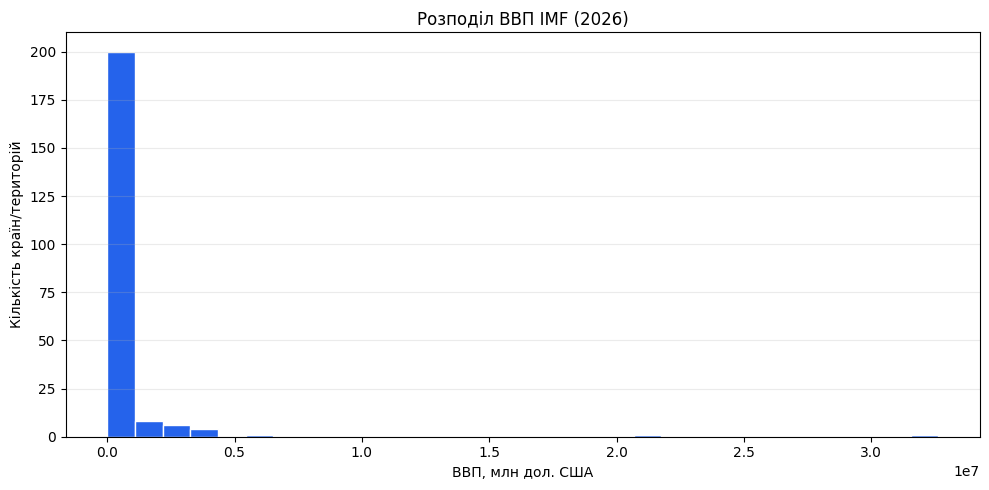

Асиметрія: 9.743 — правостороння
Найбільші верхні викиди за правилом 1,5 IQR:


,Country,IMF (2026)
0,United States,32642373.0
1,China,21546403.0
2,Germany,5471299.0
3,Japan,4341986.0
4,United Kingdom,4268446.0
5,India,4060207.0
6,France,3554155.0
7,Russia,2861156.0
8,Italy,2701737.0
9,Brazil,2654761.0


In [23]:
fig, ax = plt.subplots(figsize=(10,5))
ax.hist(df[GDP[0]], bins=30, color='#2563eb', edgecolor='white')
ax.set(title='Розподіл ВВП IMF (2026)', xlabel='ВВП, млн дол. США', ylabel='Кількість країн/територій')
ax.grid(axis='y', alpha=.25)
plt.tight_layout(); plt.show()
skew = df[GDP[0]].skew()
q1,q3 = df[GDP[0]].quantile([.25,.75])
outliers = df.loc[df[GDP[0]] > q3 + 1.5*(q3-q1), ['Country', GDP[0]]].sort_values(GDP[0], ascending=False)
print('Асиметрія:', round(skew,3), '—', 'правостороння' if skew > .5 else 'лівостороння' if skew < -.5 else 'приблизно симетрична')
print('Найбільші верхні викиди за правилом 1,5 IQR:')
display(outliers.head(10))

14.	Розрахуйте частку кожної країни в загальному значенні для кожного року (IMF (2026), World Bank (2025), United Nations (2024)).
 Як змінюються частки країн з часом (дати відповідь)?

In [24]:
shares = df[GDP].div(df[GDP].sum()).mul(100)
shares.insert(0, 'Country', df['Country'])
shares['Зміна частки 2024–2026, в.п.'] = shares[GDP[0]] - shares[GDP[2]]
display(shares)
change = 'Зміна частки 2024–2026, в.п.'
print('Найбільше зростання частки:'); display(shares.nlargest(5, change))
print('Найбільше скорочення частки:'); display(shares.nsmallest(5, change))
assert np.allclose(shares[GDP].sum(),100)
print('Частки розраховано від суми очищеного датасета, без рядка World.')

,Country,IMF (2026),World Bank (2025),United Nations (2024),"Зміна частки 2024–2026, в.п."
0,United States,22.077228,22.239355,25.372702,-3.295474
1,China,14.572619,14.092559,16.232538,-1.659919
2,Germany,3.700439,3.650646,4.035599,-0.335160
3,Japan,2.936644,3.205594,3.486786,-0.550142
4,United Kingdom,2.886906,2.892943,3.192053,-0.305147
...,...,...,...,...,...
216,Palau,0.000255,0.000249,0.000268,-0.000013
217,Marshall Islands,0.000231,0.000223,0.000243,-0.000012
218,Nauru,0.000133,0.000127,0.000162,-0.000029
219,Montserrat,0.452489,0.452489,0.000070,0.452419


Найбільше зростання частки:


,Country,IMF (2026),World Bank (2025),United Nations (2024),"Зміна частки 2024–2026, в.п."
219,Montserrat,0.452489,0.452489,0.000070,0.452419
214,Cook Islands,0.452489,0.452489,0.000359,0.452130
213,Anguilla,0.452489,0.452489,0.000395,0.452094
196,Sint Maarten,0.452489,0.001365,0.001446,0.451042
200,Turks and Caicos Islands,0.452489,0.452489,0.001522,0.450967


Найбільше скорочення частки:


,Country,IMF (2026),World Bank (2025),United Nations (2024),"Зміна частки 2024–2026, в.п."
0,United States,22.077228,22.239355,25.372702,-3.295474
1,China,14.572619,14.092559,16.232538,-1.659919
5,India,2.746066,2.859319,3.422729,-0.676663
3,Japan,2.936644,3.205594,3.486786,-0.550142
2,Germany,3.700439,3.650646,4.035599,-0.335160


Частки розраховано від суми очищеного датасета, без рядка World.


15.	Візуалізуйте зміни в показниках для кожної країни за три роки на графіку. Які країни показують стабільне зростання або спад (дати відповідь)?

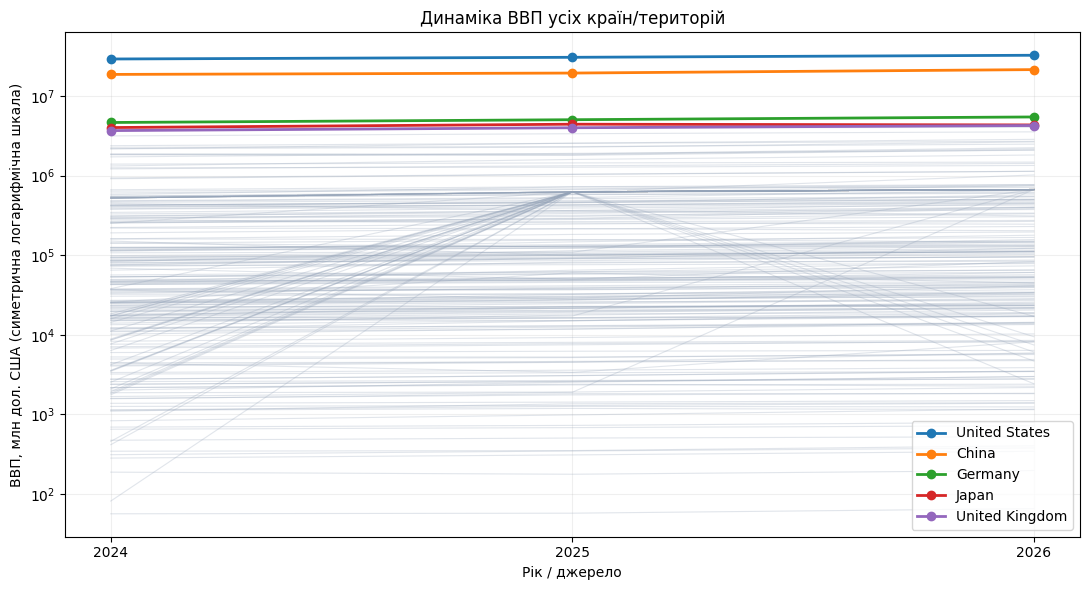

Послідовне зростання (157): United States, China, Germany, United Kingdom, India, France, Russia, Italy, Brazil, Canada, Spain, Turkey, Indonesia, Netherlands, Saudi Arabia, Switzerland, Poland, Belgium, Argentina, Israel, Sweden, Singapore, Norway, Austria, Thailand, Colombia, Malaysia, Vietnam, Bangladesh, Philippines, Denmark, South Africa, Romania, Hong Kong, Pakistan, Egypt, Czech Republic, Chile, Peru, Kazakhstan, Nigeria, Portugal, Finland, Algeria, Greece, New Zealand, Hungary, Ukraine, Morocco, Uzbekistan, Slovakia, Angola, Kenya, Bulgaria, Dominican Republic, Ecuador, Puerto Rico, Guatemala, Ghana, DR Congo, Oman, Croatia, Ivory Coast, Serbia, Luxembourg, Costa Rica, Lithuania, Belarus, Uruguay, Panama, Tanzania, Slovenia, Myanmar, Bolivia, Azerbaijan, Uganda, Cameroon, Jordan, Tunisia, Paraguay, Zimbabwe, Macau, Latvia, Cambodia, Estonia, Nepal, Cyprus, Iceland, Georgia, Honduras, Zambia, Senegal, El Salvador, Haiti, Bosnia and Herzegovina, Papua New Guinea, Guyana, Mali, Al

In [25]:
years = [2024,2025,2026]
chron = GDP[::-1]
fig, ax = plt.subplots(figsize=(11,6))
values = df[chron].to_numpy()
ax.plot(years, values.T, color='#94a3b8', alpha=.28, linewidth=.8)
for idx in df[GDP[0]].nlargest(5).index:
    ax.plot(years, df.loc[idx,chron].to_numpy(dtype=float), marker='o', linewidth=2, label=df.loc[idx,'Country'])
ax.set_yscale('symlog', linthresh=1)
ax.set(title='Динаміка ВВП усіх країн/територій', xlabel='Рік / джерело', ylabel='ВВП, млн дол. США (симетрична логарифмічна шкала)', xticks=years)
ax.legend(); ax.grid(alpha=.2); plt.tight_layout(); plt.show()
# Визначаємо тренди тільки за трьома наявними показниками, без імпутації.
complete = observed.all(axis=1)
growth = df.loc[complete & (df[chron[0]] < df[chron[1]]) & (df[chron[1]] < df[chron[2]]), 'Country']
decline = df.loc[complete & (df[chron[0]] > df[chron[1]]) & (df[chron[1]] > df[chron[2]]), 'Country']
print(f'Послідовне зростання ({len(growth)}):', ', '.join(growth) or 'немає')
print(f'Послідовний спад ({len(decline)}):', ', '.join(decline) or 'немає')
print('Різні джерела і прогноз IMF не є єдиним узгодженим часовим рядом.')

## Висновок
У роботі реалізовано завантаження таблиці ВВП, очищення, заповнення пропусків, описову статистику, порівняння показників, кореляцію, частки та візуалізацію. Конкретні країни й числові висновки автоматично виводяться після запуску. Заповнення середнім виконано за умовою завдання; воно може спотворювати оцінки для країн без вихідних даних.

**Джерело:** [Wikipedia — List of countries by GDP (nominal)](https://en.wikipedia.org/wiki/List_of_countries_by_GDP_(nominal)). Для виконання потрібен інтернет; у разі зміни років у таблиці код явно повідомить про це.